# Local Volume (d < 150 ly): Stellar Population & Exoplanets

Analysis of the complete Gaia DR3 + NASA Exoplanet Archive catalog within 150 light-years of the Sun.

**Data:** Gaia DR3 (38,847 sources), NASA Exoplanet Archive (877 planets)
**Convention:** All quantities in astropy units; distances in ly and pc.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
from astropy.coordinates import SkyCoord
import warnings
warnings.filterwarnings('ignore')

BASE = '/home/dawe/Projects/astro-science/research/projects/local-volume'
gaia = pd.read_csv(f'{BASE}/data/processed/local_volume_gaia_full.csv')
exo = pd.read_csv(f'{BASE}/data/processed/local_volume_exoplanets.csv')
print(f'Gaia sources: {len(gaia):,}')
print(f'Exoplanets: {len(exo):,}')
print(f'Unique exoplanet hosts: {exo["hostname"].nunique()}')


Gaia sources: 38,847
Exoplanets: 877
Unique exoplanet hosts: 560


## 1. Distance distribution

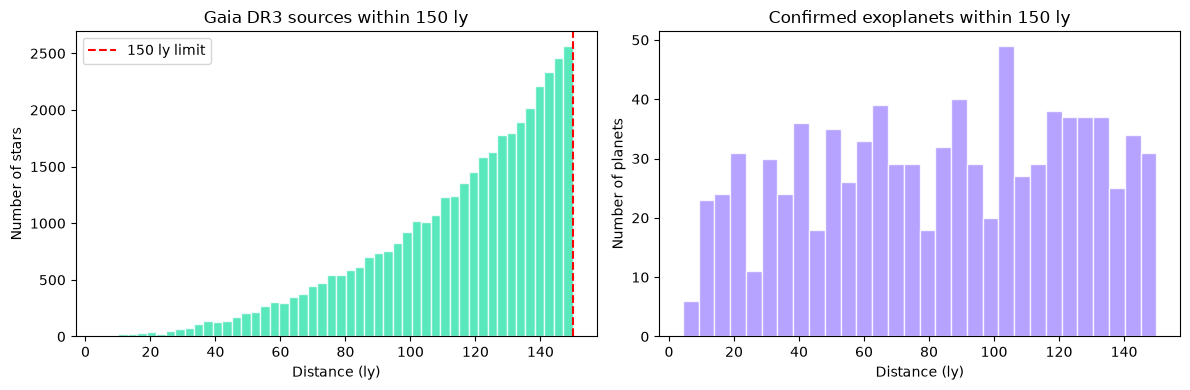

Median star distance: 122.4 ly
Median planet distance: 86.1 ly


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(gaia['distance_ly'], bins=50, color='#2fe3ac', edgecolor='white', alpha=0.8)
axes[0].set_xlabel('Distance (ly)')
axes[0].set_ylabel('Number of stars')
axes[0].set_title('Gaia DR3 sources within 150 ly')
axes[0].axvline(150, color='red', linestyle='--', label='150 ly limit')
axes[0].legend()

axes[1].hist(exo['distance_ly'], bins=30, color='#a48bff', edgecolor='white', alpha=0.8)
axes[1].set_xlabel('Distance (ly)')
axes[1].set_ylabel('Number of planets')
axes[1].set_title('Confirmed exoplanets within 150 ly')
plt.tight_layout()
plt.show()
print(f'Median star distance: {gaia["distance_ly"].median():.1f} ly')
print(f'Median planet distance: {exo["distance_ly"].median():.1f} ly')


## 2. Hertzsprung-Russell diagram

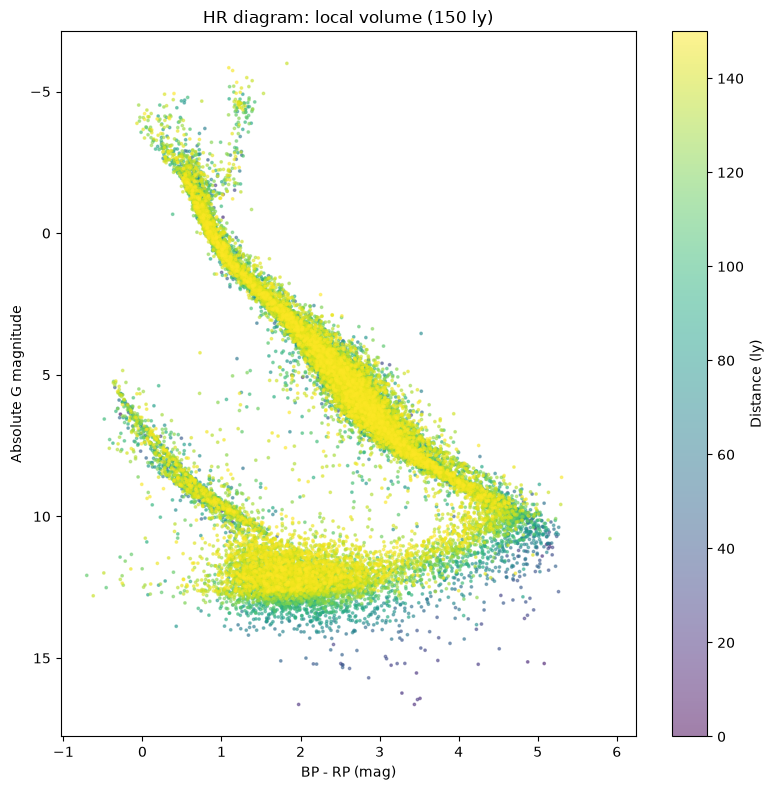

Stars with photometry: 36,153


In [3]:
has_photo = gaia['bp_rp'].notna() & gaia['abs_mag_g'].notna()
d = gaia[has_photo]
fig, ax = plt.subplots(figsize=(8, 8))
sc = ax.scatter(d['bp_rp'], d['abs_mag_g'], c=d['distance_ly'], cmap='viridis',
                s=3, alpha=0.5, vmin=0, vmax=150)
ax.invert_yaxis()
ax.set_xlabel('BP - RP (mag)')
ax.set_ylabel('Absolute G magnitude')
ax.set_title('HR diagram: local volume (150 ly)')
plt.colorbar(sc, label='Distance (ly)')
plt.tight_layout()
plt.show()
print(f'Stars with photometry: {has_photo.sum():,}')


## 3. Exoplanet demographics

Discovery methods:
discoverymethod
Radial Velocity              618
Transit                      224
Imaging                       28
Astrometry                     3
Eclipse Timing Variations      2
Transit Timing Variations      2
Name: count, dtype: int64

Radius distribution (Earth radii):
  min: 0.40, median: 1.73, max: 14.68
  Earth-size (<1.25 Re): 66
  Super-Earth (1.25-2 Re): 81
  Neptune (2-6 Re): 86
  Jupiter (>6 Re): 16


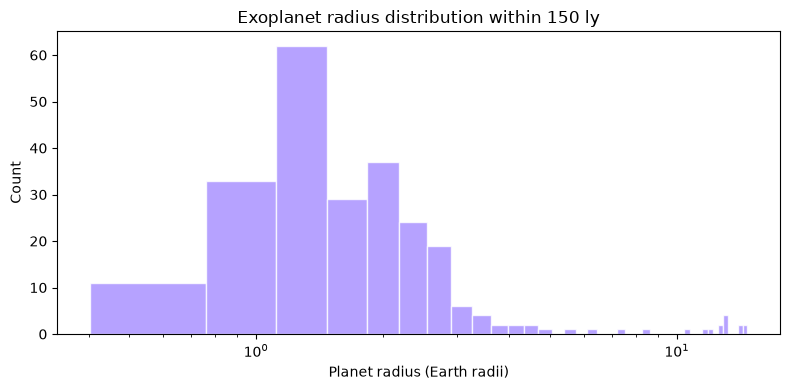

In [4]:
print('Discovery methods:')
print(exo['discoverymethod'].value_counts())
print()
print('Radius distribution (Earth radii):')
r = exo['pl_rade'].dropna()
print(f'  min: {r.min():.2f}, median: {r.median():.2f}, max: {r.max():.2f}')
print(f'  Earth-size (<1.25 Re): {(r < 1.25).sum()}')
print(f'  Super-Earth (1.25-2 Re): {((r >= 1.25) & (r < 2)).sum()}')
print(f'  Neptune (2-6 Re): {((r >= 2) & (r < 6)).sum()}')
print(f'  Jupiter (>6 Re): {(r >= 6).sum()}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(r, bins=40, color='#a48bff', edgecolor='white', alpha=0.8)
ax.set_xlabel('Planet radius (Earth radii)')
ax.set_ylabel('Count')
ax.set_title('Exoplanet radius distribution within 150 ly')
ax.set_xscale('log')
plt.tight_layout()
plt.show()


## 4. Habitability assessment

Planets in the habitable zone (equilibrium temp 200-350 K, radius < 2 Earth radii).

In [5]:
hz = exo[(exo['pl_eqt'] >= 200) & (exo['pl_eqt'] <= 350) & (exo['pl_rade'] < 2) & (exo['pl_rade'].notna())]
print(f'Habitable-zone candidates (Teq 200-350K, R<2 Re): {len(hz)}')
if len(hz) > 0:
    print(hz[['pl_name', 'hostname', 'sy_dist', 'pl_rade', 'pl_eqt', 'pl_orbper']].to_string(index=False))


Habitable-zone candidates (Teq 200-350K, R<2 Re): 13
   pl_name hostname  sy_dist  pl_rade  pl_eqt  pl_orbper
    K2-3 d     K2-3  44.0727    1.458   305.2  44.556030
LHS 1140 b LHS 1140  14.9861    1.730   226.0  24.737230
TOI-1266 c TOI-1266  36.0118    1.980   346.0  18.802700
TOI-1452 b TOI-1452  30.5212    1.672   326.0  11.062010
LP 890-9 c LP 890-9  32.4298    1.367   272.0   8.457463
 TOI-715 b  TOI-715  42.4048    1.550   234.0  19.288004
TOI-2095 b TOI-2095  41.9176    1.250   347.0  17.664840
TOI-2095 c TOI-2095  41.9176    1.330   297.0  28.172320
TOI-6002 b TOI-6002  32.0266    1.650   321.4  10.904821
TOI-5713 b TOI-5713  40.8668    1.770   347.2  10.441989
TOI-5799 c TOI-5799  27.8123    1.760   337.0  14.010449
LHS 1903 e LHS 1903  35.6917    1.732   333.0  29.317730
 TOI-789 d  TOI-789  43.4070    1.400   336.0  12.970689


## 5. Compact objects within 150 ly

Known stellar-mass black holes and neutron stars are all beyond 150 ly.
This is a scientifically important null result for the local volume.

In [6]:
compact = pd.DataFrame({
    'object': ['Gaia BH1', 'Gaia BH2', 'Gaia BH3', 'RX J1856.5-3754', 'RX J0720.4-3125'],
    'type': ['BH', 'BH', 'BH', 'NS', 'NS'],
    'distance_pc': [480, 1160, 590, 120, 300],
    'distance_ly': [1565, 3785, 1924, 391, 978],
})
compact['within_150ly'] = compact['distance_ly'] < 150
print(compact.to_string(index=False))
print()
print(f'Compact objects within 150 ly: {compact["within_150ly"].sum()}')
print('Conclusion: The local volume (150 ly) contains NO known black holes or neutron stars.')
print('It contains only main-sequence stars, white dwarfs, brown dwarfs, and exoplanets.')


         object type  distance_pc  distance_ly  within_150ly
       Gaia BH1   BH          480         1565         False
       Gaia BH2   BH         1160         3785         False
       Gaia BH3   BH          590         1924         False
RX J1856.5-3754   NS          120          391         False
RX J0720.4-3125   NS          300          978         False

Compact objects within 150 ly: 0
Conclusion: The local volume (150 ly) contains NO known black holes or neutron stars.
It contains only main-sequence stars, white dwarfs, brown dwarfs, and exoplanets.


## 6. White dwarfs and brown dwarfs

Filter the Gaia catalog for cool/late-type sources (approximate).

In [7]:
# Approximate WD/brown dwarf selection by color and absolute magnitude
cool = gaia[(gaia['bp_rp'] > 2.5) & (gaia['abs_mag_g'].notna())]
print(f'Cool/red sources (BP-RP > 2.5): {len(cool):,}')
print(f'  with Teff: {cool["teff_gspphot"].notna().sum() if "teff_gspphot" in cool.columns else "N/A"}')
print(f'  median distance: {cool["distance_ly"].median():.1f} ly')


Cool/red sources (BP-RP > 2.5): 17,890
  with Teff: 6090
  median distance: 119.4 ly
